# Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from model import HourlySeries
from simulations import StructuralModel, Simulation
from estimation import IVOptions, ModelInputParams, interval
from database import Areas
from synthetic import NonLinearDemand, Consumption, RandomCached, average_supply_price, Supply, get_wind_series, WindOptions, NonLinEquilibrium, IndividualDemand
from synthetic import SUPPLY_INTERCEPT, SUPPLY_SIGMA, SUPPLY_SLOPE

In [2]:
WIND_LAGS: int = 26

ESTIMATORS = [
    ModelInputParams(IVOptions.REGULAR, order=WIND_LAGS),
    ModelInputParams(IVOptions.CONDITIONAL_WIND, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_REGULAR, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_WIND_CAPPED, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=WIND_LAGS),
]

ESTIMATORS = [
    ModelInputParams(IVOptions.NL_REGULAR, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1, order_w=0),
    ModelInputParams(IVOptions.CONDITIONAL_H0, order=WIND_LAGS),
    # ModelInputParams(IVOptions.NL_CONDITIONAL_H0, order=WIND_LAGS),
    ModelInputParams(IVOptions.NL_TRUNCATED_NUISANCE_ORDER, order=WIND_LAGS, order_d=1),
    ModelInputParams(IVOptions.NL_CLEAN_2dim_ORDER, order=WIND_LAGS, order_price=1),
    ModelInputParams(IVOptions.NL_TRUNCATED_IV_2dim_ORDER, order=WIND_LAGS, order_price=1),
    ModelInputParams(IVOptions.NL_IV_2dim_ORDER, order=WIND_LAGS, order_price=1),
]

AREA = Areas.DE2


In [3]:
sample: int = 8760*1
runs: int = 1
model:StructuralModel = StructuralModel.Model_V
wind_manual_ar_sum: float | None = None

INTERVAL = interval(
    start=pd.Timestamp("201901010000"), end=pd.Timestamp("201901010000")+pd.Timedelta(hours=sample)
)

SERIES = HourlySeries(INTERVAL)

# Testing

In [4]:
consumption_analysis_interval: pd.DatetimeIndex = interval(
        start=pd.Timestamp("201901010000"), end=pd.Timestamp("202001282300")
    )

average_demand = Consumption(
            start=consumption_analysis_interval.min(),
            end=consumption_analysis_interval.max(),
            price_area=AREA,
        )().mean()

average_price = average_supply_price(
            quantity=average_demand,
            series=HourlySeries(consumption_analysis_interval),
            price_area=AREA,
        )

In [5]:
SUPPLY = Supply(
    price_area=AREA,
    wind=get_wind_series(
        wind_type=WindOptions.SYNTHETIC_AR_N,
        series=SERIES,
        price_area=AREA,
        synthetic_nlags=WIND_LAGS,
        synthetic_n_observations=sample,
        manual_lags_sum=wind_manual_ar_sum,
    ),
    error=RandomCached.normal(0, SUPPLY_SIGMA),
    slope=SUPPLY_SLOPE,
    intercept=SUPPLY_INTERCEPT,
)

In [6]:
price = 57
(9000 + price * (-80) + price**2 * (-0.05)) / 0.1

42775.5

In [7]:
DEMAND = NonLinearDemand(
    base_constant=average_demand,
    lags={-1: 0.9},
    b_lin=-50,
    b_sqr=-0.5,
    error=RandomCached.normal(0, 2000),
    average_supply_price=average_price,
    cross_price_elasticity={},
)
LIN_DEMAND = IndividualDemand(
    base_constant=average_demand,
    lags={-1: 0.9},
    elasticity=-100,
    error=RandomCached.normal(0, 2000),
    average_supply_price=average_price,
    cross_price_elasticity={},
)
print(f"Constant term = {DEMAND.constant}, {DEMAND.base_constant}")
print(f"At price = 0, {DEMAND(0, time=consumption_analysis_interval.min(), lagged_price={-1:0}, lagged_demand={-1:DEMAND.base_constant})} MW")
print(f"Fallback = {DEMAND.fallback(None)} MW")

Constant term = 8394.155084323478, 57658.519189991515
At price = 0, 63370.1780364306 MW
Fallback = 39196.55084323479 MW


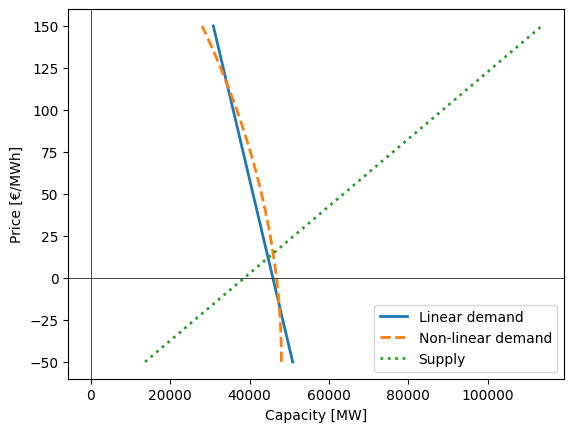

In [8]:
prices = np.linspace(-50, 150, num=1000)
demand = []
for t in range(1000):
    demand.append(DEMAND(
        price=prices[t],
        time=consumption_analysis_interval[0],
        lagged_price={-1:0},
        lagged_demand={-1:DEMAND.fallback(None)},
    ))

supply = [SUPPLY(prices[t], consumption_analysis_interval[0]) for t in range(len(prices))]
lin_demand = [LIN_DEMAND(prices[t], consumption_analysis_interval[0], lagged_price={-1:0}, lagged_demand={-1:LIN_DEMAND.fallback(None)}) for t in range(len(prices))]

plt.plot(lin_demand, prices, lw=2, label="Linear demand")
plt.plot(demand, prices, lw=2, label="Non-linear demand", ls="--")
plt.plot(supply, prices, lw=2, label="Supply", ls=":")
plt.axhline(0, ls="-", c="k", lw=0.5)
plt.axvline(0, ls="-", c="k", lw=0.5)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.legend()

In [9]:
EQUILIBRIUM = NonLinEquilibrium(
    supply=SUPPLY, 
    demand=DEMAND,
    times=INTERVAL,
    analytical_solution=True
)
EQUILIBRIUM.clearing.demand

2019-01-29 00:00:00+01:00    51408.491884
2019-01-29 01:00:00+01:00    52722.744990
2019-01-29 02:00:00+01:00    51933.501748
2019-01-29 03:00:00+01:00    53586.280175
2019-01-29 04:00:00+01:00    53569.272494
                                 ...     
2019-12-31 20:00:00+01:00    67744.398944
2019-12-31 21:00:00+01:00    65365.500839
2019-12-31 22:00:00+01:00    66139.767972
2019-12-31 23:00:00+01:00    64408.704882
2020-01-01 00:00:00+01:00    62282.369862
Freq: h, Name: demand, Length: 8089, dtype: float64

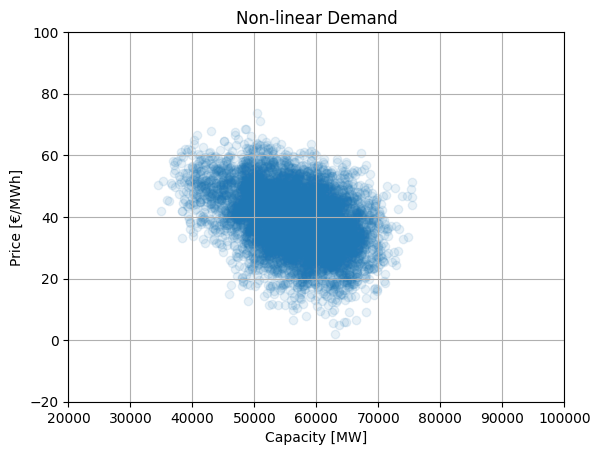

In [10]:
plt.scatter(EQUILIBRIUM.clearing.demand, EQUILIBRIUM.clearing.price, alpha=0.1)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.title("Non-linear Demand")
plt.xlim(20_000, 100_000)
plt.ylim(-20, 100)
plt.grid(True)


In [11]:
from synthetic import IndEquilibrium


LIN_EQUILIBRIUM = IndEquilibrium(
    supply=SUPPLY, 
    demand=LIN_DEMAND,
    times=INTERVAL,
    analytical_solution=True
)

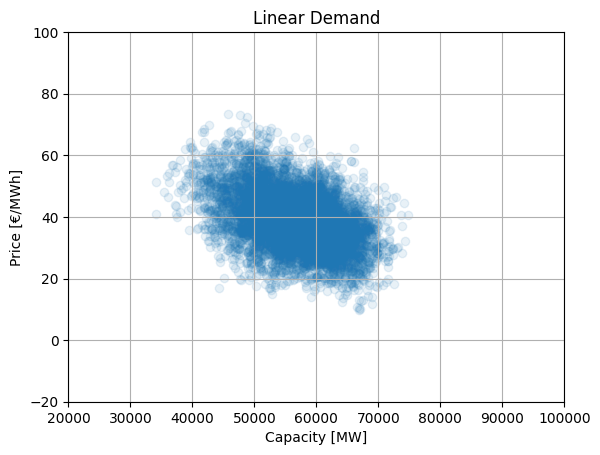

In [12]:
plt.scatter(LIN_EQUILIBRIUM.clearing.demand, LIN_EQUILIBRIUM.clearing.price, alpha=0.1)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.title("Linear Demand")
plt.xlim(20_000, 100_000)
plt.ylim(-20, 100)
plt.grid(True)


# Simulations

In [13]:
# # Create the empty lists to store the analysis output
# output_lists:dict[str, dict[str, list]] = {}
# for estimator in ESTIMATORS:
#     output_lists[estimator.name] = {"Mean":[],
#                                     "Upper":[],
#                                     "Lower":[]}



# simulation = Simulation(sample=sample)

# simulation.run_simulations_by_model(
#     runs=runs,
#     estimators=ESTIMATORS,
#     model=StructuralModel.Model_V,
#     demand_arg=0.9,
#     simulation_count=0,
#     wind_manual_ar_sum=wind_manual_ar_sum
# )

In [14]:
# simulation.report_as_text()

In [15]:
# simulation.models["I(W0, W0^2)-E(P0, P0^2)-C(W1:W26)_P0"]

## Plotting

In [16]:
from plot_tools import *
from matplotlib.axes import Axes
from matplotlib.lines import Line2D
import mpl_toolkits.axisartist as axisartist

In [17]:
def run_model_simulation(sample:int, estimators:list[ModelInputParams], runs:int, model:StructuralModel) -> tuple[list[list[float]], list[list[float]], list[list[float]], list[str]]:
    simulation = Simulation(sample=sample)

    
    simulation.run_simulations_by_model(runs=runs,
                                        estimators=estimators,
                                        model=model,
                                        demand_arg=0.7 if model in [StructuralModel.Model_I, StructuralModel.Model_V] else None,
                                        progress=False)
    
    results_p0:list[list[float]] = []
    results_p1:list[list[float]] = []
    results_psqr:list[list[float]] = []
    names = [est.latex_name for est in estimators]
    prev_model = list(simulation.models.keys())[0].split("_")[0]

    for name, estimator_results in simulation.models.items():
        # print(name, estimator_results.results)

        new_model = name.split("_")[0]
        if new_model != prev_model:
            prev_model = new_model
            for res_list in [results_p1, results_psqr]:
                if len(res_list) < len(results_p0):
                    res_list.append([])
                
        if "_" not in name or name.endswith("_P0"):
            results_p0.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P1"):
            results_p1.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P0^2"):
            results_psqr.append([res.estimate for res in estimator_results.results])
        else:
            pass
            # print(name)
    # This is needed just in case the last one also does not have an estimate for all of them!
    for res_list in [results_p1, results_psqr]:
        if len(res_list) < len(results_p0):
            res_list.append([])

    return results_p0, results_p1, results_psqr, names

In [18]:
def application_boxplot(results_p0:list[list[float]],
                        results_p1:list[list[float]], 
                        results_psqr:list[list[float]], 
                        names:list[str], 
                        output_file:str, 
                        xlim, 
                        own_price_elasticity, 
                        cross_price_elasticity,
                        quadratic_elasticity,
                        replace_ellipsis:bool):
        total_width = (WIDE_WIDTH-1) + 4
        fig, axss = plt.subplots(1, 2, sharex=False,  sharey=True, figsize=(total_width, HEIGHT), width_ratios=[(WIDE_WIDTH-1)/total_width, 4/total_width], subplot_kw={'axes_class': axisartist.Axes})
        # fig, ax0 = plt.subplots(1, 1, sharex=False,  sharey=True, figsize=(WIDE_WIDTH, HEIGHT), subplot_kw={'axes_class': axisartist.Axes})
        ax0: Axes = axss[0]
        ax1: Axes = axss[1]

        names = [f"#{i+1}   {n} " for i, n in enumerate(names)]
        if replace_ellipsis:
             names = [func_replace_ellipsis(name) for name in names]
        xx_p0: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p0]))
        xx_p1: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p1]))
        xx_psqr: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_psqr]))
       
        ticks: list[str] = list(reversed(names))
   
        bplot1 = ax0.boxplot(xx_p0, vert=False, patch_artist=True)
        bplot2 = ax0.boxplot(xx_p1, vert=False, patch_artist=True, notch=True)
        bplot3 = ax1.boxplot(xx_psqr, vert=False, patch_artist=True, notch=False)
   
        colors = ["darkorange", "dodgerblue", "darkgreen"]
        bbpp = [bplot1, bplot2, bplot3]
   
        for plot, color in zip(bbpp, colors):
            for patch in plot['boxes']:
                patch.set_facecolor(color)
            for median in plot['medians']:
                median.set_color('black')
   
        legend_elements = [
            bplot1["boxes"][0], 
            bplot2["boxes"][0],
            bplot3["boxes"][0],
            Line2D([0], [0], color='darkorange', linestyle="--",),
            Line2D([0], [0], color='dodgerblue', linestyle=":",),
            Line2D([0], [0], color='darkgreen', linestyle="--",),
        ]
        legend_labels = [
            "estimated linear own-price demand response $\\hat{\\beta}^{PL}$ (part of $P_t\\rightarrow D_t$)", 
            "estimated cross-price demand response $\\hat{\\beta}^{P1}$ ($P_{t-1}\\rightarrow D_t$)",
            "estimated quadratic own-price demand response $\\hat{\\beta}^{PS}$ (part of $P_t\\rightarrow D_t$)", 
            "true linear own-price demand response $\\beta^{PL}$",
            "true cross-price demand response $\\beta^{P1}$",
            "true quadratic own-price demand response $\\beta^{PS}$",
        ]
   
        ax0.tick_params(axis='y', which='both', left=False, labelleft=True, reset=True)
   
        ax0.set_yticks(range(1, len(ticks)+1))
        ax0.set_yticklabels(ticks, fontsize="large")
        ax0.yaxis.grid(visible=False)
        ax0.axis["left"].major_ticklabels.set_ha("left")    # type: ignore
        ax0.axis["left"].major_ticks.set_ticksize(0)        # type: ignore
        
        ax0.set_ylim(0.5, len(ticks)+0.5)
        ax0.set_xlim(xlim)
        
        ax0.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax0.axvline(x=own_price_elasticity, ls='--', color='darkorange', lw=2, alpha=1)
        ax0.axvline(x=cross_price_elasticity, ls=':', color='dodgerblue', lw=2, alpha=1)
        ax1.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax1.axvline(x=quadratic_elasticity, ls='--', color='darkgreen', lw=2, alpha=1)
   
        for h in range(0, len(xx_p0)+1):
                ax0.axhline(y=h + 0.5, ls="-", color="grey", xmin=-0.425, xmax=1, clip_on=False)
                ax1.axhline(y=h + 0.5, ls="-", color="grey", xmin=0, xmax=1, clip_on=False)
    
        # Add estimator validity table
        # plot_table(fig)
        
        
        # Remove duplicate y ticks from right subplot
        ax1.axis["left"].set_visible(False)    # type: ignore
        ax1.axvline(ax1.get_xlim()[0], ls="-", color="k", clip_on=False, lw=0.5)

        # Add the legend to the figure,
        fig.legend(handles=legend_elements, labels=legend_labels, loc='upper center', 
                   ncol=2, bbox_to_anchor=(0.5, 0), fancybox=True, frameon=False, fontsize="large")
    
        save_figure(fig, output_file+"_application_figure", VERSION)
   
  

In [19]:
def plot_application_boxplot(sample:int, runs:int, output_file:str, model:StructuralModel, estimators:list[ModelInputParams]):
    
    results_p0, results_p1, results_psqr, names = run_model_simulation(
        model=model,
        estimators=estimators,
        sample=sample,
        runs=runs
    )
    
    xlims:dict[StructuralModel, tuple[float, float]] = {
        StructuralModel.Model_I:(-400, 100),
        StructuralModel.Model_II:(-200, 100),
        StructuralModel.Model_III:(-200, 100),
        StructuralModel.Model_V:(-200, 100),
    }

    application_boxplot(
        results_p0=results_p0,
        results_p1=results_p1,
        results_psqr=results_psqr,
        names=names,
        output_file=output_file,
        xlim=xlims[model],
        own_price_elasticity=-100 if model != StructuralModel.Model_V else -50,
        cross_price_elasticity=50 if model == StructuralModel.Model_III else 0,
        quadratic_elasticity=-0.5,
        replace_ellipsis=False
    )

100%|██████████| 1/1 [00:59<00:00, 59.86s/it]


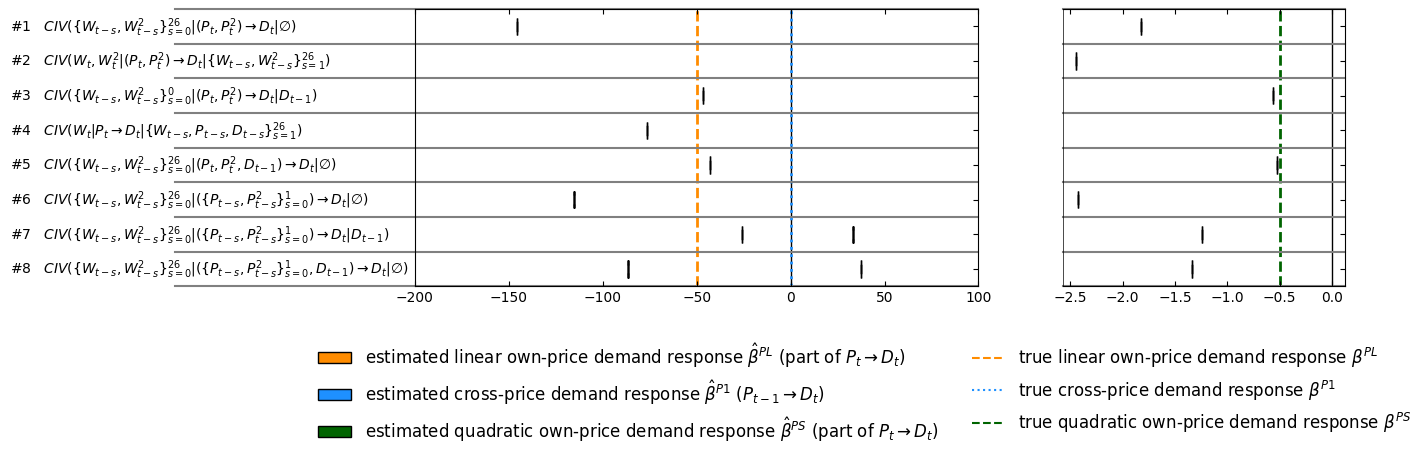

In [20]:
plot_application_boxplot(8760*1, 1, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)

100%|██████████| 10/10 [3:16:00<00:00, 1176.00s/it]  


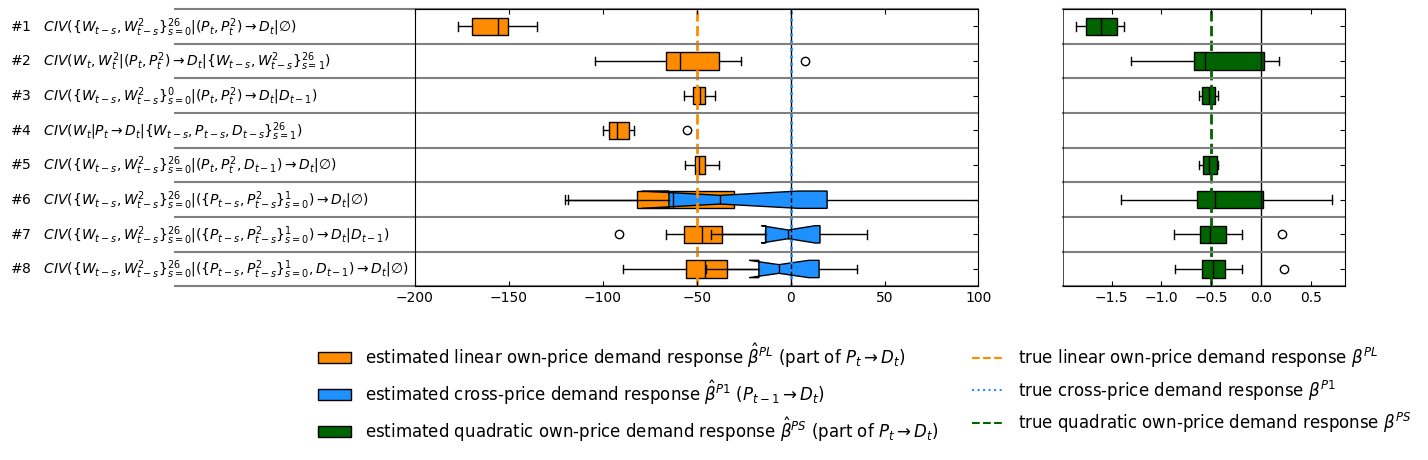

In [21]:
plot_application_boxplot(8760*2, 10, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)


100%|██████████| 100/100 [36:45:33<00:00, 1323.33s/it]   


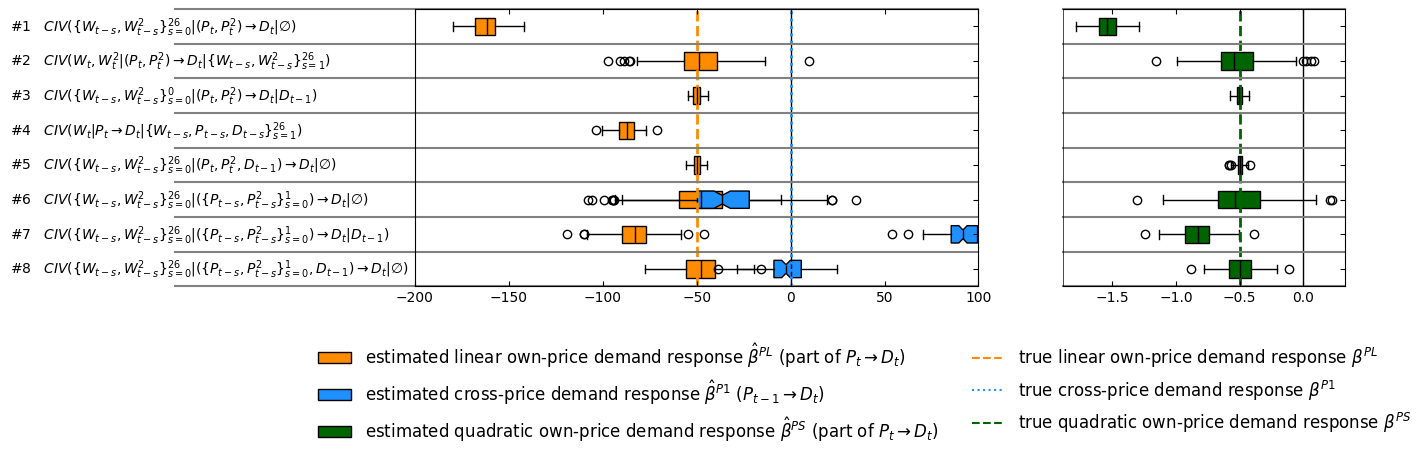

In [21]:
plot_application_boxplot(8760*10, 100, "model_V_10_years_100_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [22]:
plot_application_boxplot(8760*25, 50, "model_V_25_years_50_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

  0%|          | 0/50 [00:00<?, ?it/s]

Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['price', 'constant'] to ensure full column rank!

constant should be dropped
price should be dropped
Columns reduced from 55 to 53
'price'
Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['price', 'constant'] to ensure full column rank!

constant should be dropped
price should be dropped
Columns reduced from 55 to 53
'price'
Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['constant'] to ensure full column rank!

constant should be dropped
Columns reduced from 55 to 54


  2%|▏         | 1/50 [43:47<35:46:05, 2627.86s/it]

Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['constant'] to ensure full column rank!

constant should be dropped
Columns reduced from 55 to 54


  4%|▍         | 2/50 [1:19:02<31:01:00, 2326.26s/it]

...

'price'
Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['price', 'constant'] to ensure full column rank!

constant should be dropped
price should be dropped
Columns reduced from 55 to 53
'price'
Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['price', 'constant'] to ensure full column rank!

constant should be dropped
price should be dropped
Columns reduced from 55 to 53
'price'
Exog
Endog
Inst
Exog and Endog


WARNING!
IVOptions.NL_CONDITIONAL_WIND
Dropping columns ['price', 'constant'] to ensure full column rank!

constant should be dropped
price should be dropped
Columns reduced from 55 to 53


 26%|██▌       | 13/50 [13:01:03<54:26:45, 5297.44s/it]

'price'


 26%|██▌       | 13/50 [13:02:10<37:06:10, 3610.01s/it]


KeyboardInterrupt: 

In [ ]:
plot_application_boxplot(8760*10, 50, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)

100%|██████████| 20/20 [1:35:35<00:00, 286.78s/it]


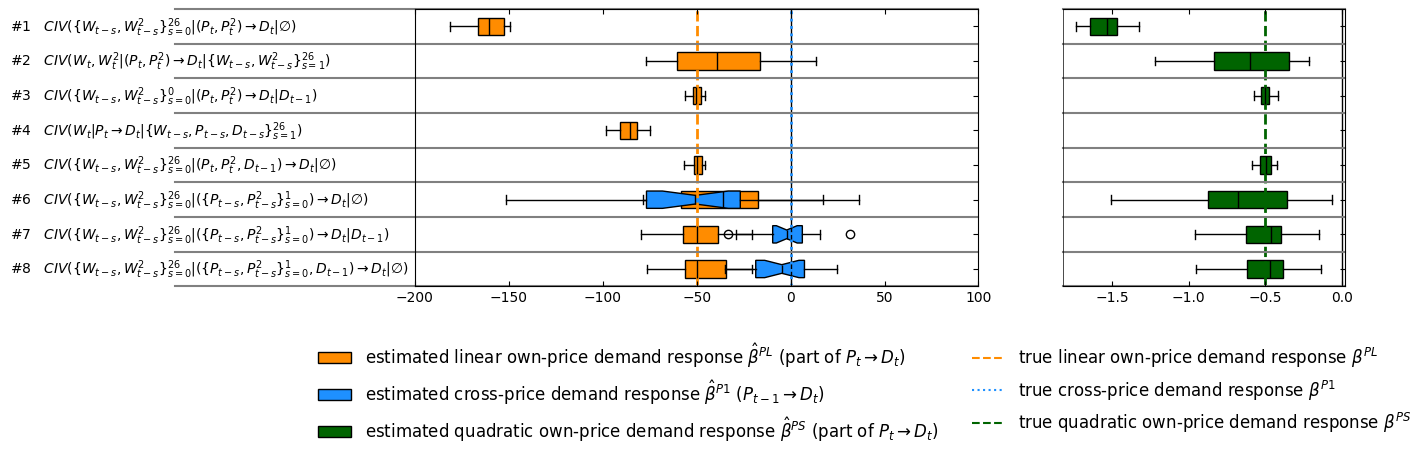

In [ ]:
plot_application_boxplot(8760*5, 20, "model_V_5_years_20_runs", StructuralModel.Model_V, estimators=ESTIMATORS)
